# Notebook 10 — SD3 Medium: causal completeness, sparse-feature scaling and semantic specificity



## 0. Set run mode (change only this cell)



In [1]:
MODE = "replication"                # "pilot" | "replication" | "analysis"
PILOT_PAIRS_PER_LABEL = 1
K_GRID_PILOT = [4, 16, 64, 256]
K_GRID_REPLICATION = [4, 8, 16, 32, 64, 128, 256, 512]
REPLICATION_SEEDS = [1, 2]
RUN_IDENTITY_CHECK = True
FORCE_RERUN = False
MAX_BOOTSTRAP = 3000


## 1. Environment, read-only previous artifacts, DataSphere storage



In [2]:
from pathlib import Path
from collections import defaultdict
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont
import ast, gc, hashlib, itertools, json, math, os, re, sys, warnings
import numpy as np
import pandas as pd
import torch

assert MODE in {"pilot", "replication", "analysis"}

def find_root():
    candidates=[]
    if os.environ.get("PROJECT_ROOT"): candidates.append(Path(os.environ["PROJECT_ROOT"]))
    wd=Path.cwd().resolve(); candidates += [wd, *wd.parents, Path("/home/jupyter/project/diffusion_attention_analysis_2")]
    for p in candidates:
        p=p.expanduser().resolve()
        if (p/"src/diffusion_attention_analysis_v2").exists() and (p/"configs").exists(): return p
    raise FileNotFoundError("Set PROJECT_ROOT to the diffusion_attention_analysis_2 repository")
PROJECT_ROOT=find_root(); os.chdir(PROJECT_ROOT)
sys.path.insert(0,str(PROJECT_ROOT/"src")) if str(PROJECT_ROOT/"src") not in sys.path else None
from diffusion_attention_analysis_v2.activations import extract_first_tensor, flatten_feature_map, unflatten_feature_map, replace_first_tensor, remove_hooks
from diffusion_attention_analysis_v2.config import load_config, deep_get, resolve_path
from diffusion_attention_analysis_v2.io_utils import module_to_filename
from diffusion_attention_analysis_v2.pipelines import load_pipeline, get_denoiser_module, generation_kwargs
from diffusion_attention_analysis_v2.sae import load_sae_checkpoint
from diffusion_attention_analysis_v2.sd3_notebook_utils import prepare_datashere_storage
RUN_TAG="sd3_medium_sae_circuit_150"
storage=prepare_datashere_storage(project_root=PROJECT_ROOT,run_tag=RUN_TAG,container_name="container4",require_container=True,min_free_gb=10.0)
assert storage["free_space_ok"], f"Insufficient free space on container4: {storage['free_gb']:.1f} GiB"
CONFIG_PATH=PROJECT_ROOT/"configs/06_causal_analysis/sd3_medium_counterfactual_sae_mediation_v2.yaml"
assert CONFIG_PATH.exists(), f"Notebook 09 config not found: {CONFIG_PATH}"
cfg=load_config(CONFIG_PATH)
PREV=resolve_path(cfg,"data.output_dir",required=True)
assert PREV.is_dir(), f"Previous notebook 09 output directory missing: {PREV}"
OUT=PROJECT_ROOT/"outputs"/RUN_TAG/"06_causal_completeness_v3"
OUT.mkdir(parents=True,exist_ok=True)
for sub in ["clean_cache", "images", "scores", "figures", "galleries", "checks"]: (OUT/sub).mkdir(parents=True,exist_ok=True)
SITE="mid"; SCFG=cfg["sites"][SITE]; MODULE=str(SCFG["module"])
WINDOW=list(map(int,SCFG["window_steps"])); PROBE_MODULE=str(cfg["sites"]["late"]["module"]); PROBE_STEP=int(cfg["sites"]["late"]["anchor_step"])
assert MODULE=="transformer_blocks.11" and WINDOW==[11,12,13,14,15]
CHECKPOINT=resolve_path(cfg,"sites.mid.sae_checkpoint",required=True)
assert CHECKPOINT.exists(), f"SAE checkpoint missing: {CHECKPOINT}"
DEVICE=str(deep_get(cfg,"model.device","cuda"))
SEEDS=[0] if MODE=="pilot" else list(REPLICATION_SEEDS)
K_GRID=K_GRID_PILOT if MODE=="pilot" else K_GRID_REPLICATION
print("Root:",PROJECT_ROOT,"\nOld artifacts (read-only):",PREV,"\nNew results:",OUT,"\nMODE:",MODE,"SEEDS:",SEEDS)


Root: /home/jupyter/project/diffusion_attention_analysis_2 
Old artifacts (read-only): /home/jupyter/project/diffusion_attention_analysis_2/outputs/sd3_medium_sae_circuit_150/06_causal_mediation_v2 
New results: /home/jupyter/project/diffusion_attention_analysis_2/outputs/sd3_medium_sae_circuit_150/06_causal_completeness_v3 
MODE: replication SEEDS: [1, 2]


## 2. Frozen pair split, SAE feature ranks and hypothesis audit



In [3]:
required=["split_manifest.csv","feature_discovery.csv","selected_features.json"]
missing=[x for x in required if not (PREV/x).exists()]
if missing: raise FileNotFoundError(f"Missing notebook 09 discovery artifacts: {missing}")
SPLIT=pd.read_csv(PREV/"split_manifest.csv")
DISC=pd.read_csv(PREV/"feature_discovery.csv"); DISC=DISC[DISC.site.eq(SITE)].copy()
FEATURE_MAP=json.loads((PREV/"selected_features.json").read_text(encoding="utf-8"))
assert SPLIT.source_id.is_unique and set(SPLIT.split)=={"discovery","evaluation","confirmatory"}, "Unexpected or leaky 09 split"
all_pairs=SPLIT[SPLIT.split.eq("confirmatory")].copy().sort_values(["label","pair_id"]).reset_index(drop=True)
assert len(all_pairs)==12 and len(all_pairs.label.unique())==6, "Expected 12 confirmatory prompt templates and six labels"
PAIR_TABLE=(all_pairs.groupby("label",group_keys=False).head(PILOT_PAIRS_PER_LABEL).copy() if MODE=="pilot" else all_pairs.copy())
PAIRS=PAIR_TABLE.to_dict("records")
RANKS={}; FEATURE_ROWS=[]
for label in sorted(all_pairs.label.unique()):
    part=DISC[DISC.label.eq(label)].copy()
    assert len(part) and not part.feature_id.duplicated().any(), f"Invalid discovery ranking for {label}"
    original=FEATURE_MAP[f"{SITE}::{label}"]["cf"]
    # From discovery-only precomputed statistics; no evaluation or confirmatory scores used here.
    sem=part.sort_values(["eligible","t_like","mean_patch_energy"],ascending=[False,False,False]).feature_id.astype(int).tolist()
    energy=part.sort_values("mean_patch_energy",ascending=False).feature_id.astype(int).tolist()
    RANKS[label]={"semantic":sem,"energy":energy,"09_selected":list(map(int,original))}
    for rank,fid in enumerate(sem[:512]):
        row=part.loc[part.feature_id.eq(fid)].iloc[0]
        FEATURE_ROWS.append({"label":label,"rank":rank+1,"feature_id":fid,"reuse_count":float(row.reuse_count),"t_like":float(row.t_like),"energy":float(row.mean_patch_energy)})
RANKS_HASH=hashlib.sha256(json.dumps(RANKS,sort_keys=True).encode()).hexdigest()[:12]
(OUT/"checks"/"feature_rank_hash.txt").write_text(RANKS_HASH)
pd.DataFrame(FEATURE_ROWS).to_csv(OUT/"feature_rank_diagnostics.csv",index=False)
print("Selected pair templates:",len(PAIRS),"Ranking hash:",RANKS_HASH)
display(PAIR_TABLE[["split","label","replacement_label","pair_id","source_prompt","destination_prompt"]])
display(pd.DataFrame(FEATURE_ROWS).query("rank<=16").groupby("label").agg(reuse_top16=("reuse_count","mean"),feature_energy=("energy","mean")))


Selected pair templates: 12 Ranking hash: 3d7f5caec73d


,split,label,replacement_label,pair_id,source_prompt,destination_prompt
0,confirmatory,bicycle,banana,sd3_circuit_055_lamp_bicycle__bicycle_to_banana,realistic photo of a lamp near a bicycle on a ...,realistic photo of a lamp near a banana on a c...
1,confirmatory,bicycle,bed,sd3_circuit_085_lamp_bicycle__bicycle_to_bed,realistic photo of a lamp near a bicycle in a ...,realistic photo of a lamp near a bed in a smal...
2,confirmatory,book,flower,sd3_circuit_076_banana_book__book_to_flower,documentary photo of a banana in front of a bo...,documentary photo of a banana in front of a fl...
3,confirmatory,book,chair,sd3_circuit_106_banana_book__book_to_chair,documentary photo of a banana in front of a bo...,documentary photo of a banana in front of a ch...
4,confirmatory,car,chair,sd3_circuit_033_book_car__car_to_chair,natural light photo of a book under a car on a...,natural light photo of a book under a chair on...
5,confirmatory,car,apple,sd3_circuit_123_book_car__car_to_apple,natural light photo of a book under a car on a...,natural light photo of a book under a apple on...
6,confirmatory,cat,flower,sd3_circuit_050_bus_cat__cat_to_flower,realistic photo of a bus beside a cat inside a...,realistic photo of a bus beside a flower insid...
7,confirmatory,cat,horse,sd3_circuit_080_bus_cat__cat_to_horse,realistic photo of a bus beside a cat on a cit...,realistic photo of a bus beside a horse on a c...
8,confirmatory,dog,bed,sd3_circuit_007_tree_dog__dog_to_bed,studio photo of a tree near a dog on a city st...,studio photo of a tree near a bed on a city st...
9,confirmatory,dog,bed,sd3_circuit_037_tree_dog__dog_to_bed,studio photo of a tree near a dog in a small park,studio photo of a tree near a bed in a small park


,reuse_top16,feature_energy
label,,
bicycle,16.5000,2.962611
book,16.0625,3.316767
car,20.3750,3.941299
cat,21.1875,3.542905
dog,21.0625,3.706614
person,16.5625,3.493979


## 3. Static algebra tests and preflight cache plan



In [4]:
def mod_part(name): return module_to_filename(name).replace(".pt", "")
def cache_base(root,pair_id,seed,role): return root/"clean_cache"/pair_id/f"seed_{seed:04d}"/role
def candidate_roots(seed): return [PREV,OUT] if seed==0 else [OUT]
def locate_ref(pair_id,seed,role,module,step):
    rel=Path(mod_part(module))/f"step_{step:03d}.pt"
    for root in candidate_roots(seed):
        p=cache_base(root,pair_id,seed,role)/rel
        if p.exists():return p
    return None
def locate_image(pair_id,seed,role):
    for root in candidate_roots(seed):
        p=cache_base(root,pair_id,seed,role)/"image.png"
        if p.exists(): return p
    return None
def flat_ref(pair_id,seed,role,module,step):
    path=locate_ref(pair_id,seed,role,module,step)
    if path is None: raise FileNotFoundError(f"Missing ref {pair_id}/{seed}/{role}/{module}/{step}")
    d=torch.load(path,map_location="cpu",weights_only=False)
    x=d["features"].float()
    assert x.ndim==2 and x.shape[1]==1536 and x.shape[0]==4096, (str(path),x.shape)
    return x

def clean_complete(pair,seed,role):
    pid=str(pair["pair_id"])
    return locate_image(pid,seed,role) is not None and all(locate_ref(pid,seed,role,MODULE,s) for s in WINDOW) and locate_ref(pid,seed,role,PROBE_MODULE,PROBE_STEP)

SCHEDULE=pd.DataFrame([{"seed":seed,"pair_id":p["pair_id"],"role":role,"cached":bool(clean_complete(p,seed,role))} for seed in SEEDS for p in PAIRS for role in ["source","destination"]])
display(SCHEDULE.groupby(["seed","role","cached"]).size().rename("n").reset_index())
# Algebraic identity for any SAE: (xhat_s - xhat_d)+(e_s-e_d) == xs-xd, irrespective of the SAE quality.
a=torch.randn(16,12); b=torch.randn(16,12); ahat=a*.65; bhat=b*.67
assert torch.allclose((ahat-bhat)+((a-ahat)-(b-bhat)),a-b,atol=1e-5)


,seed,role,cached,n
0,1,destination,False,12
1,1,source,False,12
2,2,destination,False,12
3,2,source,False,12


## 4. Generation and clean references (skip on analysis)



In [ ]:
def conditional_flat(update):
    flat,shape=flatten_feature_map(update.detach().float())
    if len(shape)!=3:raise RuntimeError(("Expected B,N,D",shape))
    b,n,d=map(int,shape)
    assert n==4096 and d==1536 and b in (1,2), (b,n,d)
    x=flat.reshape(b,n,d)
    return x[b//2:].reshape(-1,d),shape

def run_sd3(pipe,denoiser,prompt,seed,install=None):
    gen=torch.Generator(device="cuda" if DEVICE=="cuda" and torch.cuda.is_available() else "cpu").manual_seed(int(seed))
    current={"step":-1}
    def pre(module,inputs): current["step"]+=1
    root=denoiser.register_forward_pre_hook(pre)
    handles=[]
    try:
        if install: handles=list(install(lambda: current["step"]) or [])
        out=pipe(**generation_kwargs(cfg,prompt,gen))
        assert current["step"]==int(deep_get(cfg,"generation.num_inference_steps",28))-1, f"Step counter mismatch: {current}"
        return out.images[0]
    finally: remove_hooks(handles+[root])

def capture_pair(pipe,denoiser,pair,seed,role):
    pid=str(pair["pair_id"]); prompt=str(pair[f"{role}_prompt"]); modules=dict(denoiser.named_modules()); cache={}
    requested={MODULE:set(WINDOW), PROBE_MODULE:{PROBE_STEP}}
    def install(get_step):
        hs=[]
        for module,steps in requested.items():
            assert module in modules, module
            def make_hook(module,steps):
                def hook(obj,inputs,output):
                    step=int(get_step())
                    if step not in steps:return output
                    xin=extract_first_tensor(inputs)
                    xout=extract_first_tensor(output)

                    if xout is None:
                        return output

                    residual_mode = (
                        xin is not None
                        and tuple(xin.shape) == tuple(xout.shape)
                    )

                    update = xout - xin if residual_mode else xout
                    cond, _ = conditional_flat(update)
                    cache[(module,step)]=cond.to(device="cpu",dtype=torch.float16)
                    return output
                return hook
            hs.append(modules[module].register_forward_hook(make_hook(module,set(steps))))
        return hs
    im=run_sd3(pipe,denoiser,prompt,seed,install)
    expected={(MODULE,s) for s in WINDOW}|{(PROBE_MODULE,PROBE_STEP)}
    assert set(cache)==expected,("Not all reference tensors captured",set(cache),expected)
    base=cache_base(OUT,pid,seed,role);base.mkdir(parents=True,exist_ok=True)
    for (module,step),tensor in cache.items():
        path=base/mod_part(module)/f"step_{step:03d}.pt";path.parent.mkdir(parents=True,exist_ok=True)
        torch.save({"features":tensor,"module":module,"step":step},path)
    im.save(base/"image.png")

if MODE!="analysis":
    pending=[(p,s,r) for p in PAIRS for s in SEEDS for r in ("source","destination") if not clean_complete(p,s,r)]
    print("Clean trajectories to generate:",len(pending))
    if pending:
        if not torch.cuda.is_available(): raise RuntimeError("SD3 generation requires a CUDA GPU")
        pipe=load_pipeline(cfg); denoiser=get_denoiser_module(pipe)
        for j,(p,s,r) in enumerate(pending,1):
            capture_pair(pipe,denoiser,p,s,r)
            print(f"Captured {j}/{len(pending)}:",s,p['pair_id'],r)
        del pipe,denoiser; gc.collect();torch.cuda.empty_cache()
assert MODE=="analysis" or all(clean_complete(p,s,r) for p in PAIRS for s in SEEDS for r in ("source","destination"))


## 5. Frozen feature sets and dose-matched negative control



In [7]:
# The original discovery dataset contains 3072 entries per label; control ranking is fixed across all prompts/seeds.
CONTROL_MAP={}
for label in RANKS:
    df=DISC[DISC.label.eq(label)].set_index("feature_id").sort_index()
    sem=RANKS[label]["semantic"]; energy=RANKS[label]["energy"]
    forbidden=set(sem[:512]+energy[:512])
    candidate=df.loc[~df.index.isin(forbidden)].copy()
    if len(candidate)<max(K_GRID):
        candidate=df.loc[~df.index.isin(set(sem[:max(K_GRID)]))].copy()
    assert len(candidate)>=max(K_GRID)
    target=df.loc[sem[:max(K_GRID)]].copy()
    log_e=np.log1p(candidate.mean_patch_energy.clip(lower=0).astype(float))
    log_n=np.log1p(candidate.decoder_norm.clip(lower=0).astype(float))
    te=np.log1p(target.mean_patch_energy.clip(lower=0).astype(float));tn=np.log1p(target.decoder_norm.clip(lower=0).astype(float))
    distance=(log_e-te.median()).abs()+(log_n-tn.median()).abs()
    CONTROL_MAP[label]=distance.sort_values(kind="stable").index.astype(int).tolist()
FEATURE_SET={}
for label in RANKS:
    for k in K_GRID:
        FEATURE_SET[(label,f"semantic_{k}")]=RANKS[label]["semantic"][:k]
        FEATURE_SET[(label,f"energy_{k}")]=RANKS[label]["energy"][:k]
        FEATURE_SET[(label,f"control_{k}")]=CONTROL_MAP[label][:k]
    FEATURE_SET[(label,"all_sae")]=[]
print("Control sets frozen",len(CONTROL_MAP),"labels; max K:",max(K_GRID))


Control sets frozen 6 labels; max K: 512


## 6. Intervention operators and exact-identity diagnostics


In [8]:
def sae_parts(sae,current_cpu,reference_cpu,ids=None,perm=None,batch=512):
    device=sae.encoder.weight.device
    cols=None if ids is None else list(map(int,ids))
    outs=[]; hats=[]; errors=[]
    with torch.no_grad():
        for st in range(0,len(current_cpu),batch):
            xd=current_cpu[st:st+batch].to(device=device,dtype=torch.float32)
            xs=reference_cpu[st:st+batch].to(device=device,dtype=torch.float32)
            zd=sae.encode(xd);zs=sae.encode(xs)
            hd=sae.decode(zd);hs=sae.decode(zs)
            if cols is not None and len(cols):
                # The optional permutation is applied to cached source SAE latents before subtracting current destination latents.
                if perm is None:
                    dz=zs[:,cols]-zd[:,cols]
                    proj=dz@sae.decoder.weight[:,cols].T
                    outs.append(proj.float().cpu())
                else:
                    # Permutation handled in a two-pass routine below.
                    outs.append((zs[:,cols].float().cpu(),zd[:,cols].float().cpu()))
            hats.append((hs-hd).float().cpu())
            errors.append(((xs-hs)-(xd-hd)).float().cpu())
    if perm is not None:
        zsrc=torch.cat([a for a,b in outs],dim=0)
        zdst=torch.cat([b for a,b in outs],dim=0)
        direction=sae.decoder.weight[:,cols].float().detach().cpu()
        projected=(zsrc[perm]-zdst)@direction.T
    else:
        projected=torch.cat(outs) if outs else None
    return projected,torch.cat(hats),torch.cat(errors)

class CompletenessHook:
    def __init__(self,mode,ids,sae,reference_by_step,get_step,perm_seed=2601):
        self.mode=mode;self.ids=ids;self.sae=sae;self.refs=reference_by_step;self.get_step=get_step
        self.perm_seed=int(perm_seed);self.telemetry=[]
    def __call__(self,module,inputs,output):
        step=int(self.get_step())
        if step not in self.refs: return output
        xin = extract_first_tensor(inputs)
        xout = extract_first_tensor(output)

        if xout is None:
            return output

        residual_mode = (
            xin is not None
            and tuple(xin.shape) == tuple(xout.shape)
        )

        update = xout - xin if residual_mode else xout
        flat,shape=flatten_feature_map(update.detach().float()); b,n,d=map(int,shape)
        assert b in (1,2) and n==4096 and d==1536
        xb=flat.reshape(b,n,d); sl=slice(b//2,b)
        curr=xb[sl].reshape(-1,d).detach().float().cpu()
        ref=self.refs[step]
        assert ref.shape==curr.shape
        full_delta=ref-curr
        if self.mode=="full": delta=full_delta
        elif self.mode=="identity": delta=torch.zeros_like(curr)
        else:
            perm=None
            if self.mode=="permutation":
                g=torch.Generator(device="cpu").manual_seed(self.perm_seed+step)
                perm=torch.randperm(len(curr),generator=g)
            feature,hats,errors=sae_parts(self.sae,curr,ref,ids=self.ids if self.mode in ("feature","control","permutation") else None,perm=perm)
            if self.mode=="whole_sae":delta=hats
            elif self.mode=="error":delta=errors
            elif self.mode in ("feature","control","permutation"):
                delta=feature
                if self.mode in ("control","permutation"):
                    # Match RMS of top-K semantic interchange on this same current trajectory.
                    # Ref source/destination match differs across arms; this is energy, not effect matching.
                    target,h0,e0=sae_parts(self.sae,curr,ref,ids=self.reference_semantic_ids)
                    reference_rms=target.square().mean().sqrt()
                    delta=delta*(reference_rms/(delta.square().mean().sqrt()+1e-9))
            else: raise ValueError(self.mode)
        before=full_delta.square().mean().sqrt().item()
        applied=delta.square().mean().sqrt().item()
        cosine=torch.nn.functional.cosine_similarity(delta.reshape(1,-1),full_delta.reshape(1,-1)).item() if applied>0 and before>0 else 0.0
        self.telemetry.append({"step":step,"patch_rms":float(applied),"full_reference_rms":float(before),"dose_ratio":float(applied/(before+1e-9)),"delta_alignment":float(cosine)})
        xb[sl]=(curr+delta).to(xb.device,xb.dtype).reshape(xb[sl].shape)
        new_update = unflatten_feature_map(
            xb.reshape(-1, d),
            shape,
            like=xout,
        )

        new_tensor = (
            xin + new_update
            if residual_mode
            else new_update
        )

        return replace_first_tensor(
            output,
            new_tensor,
            xout.shape,
        )

def downstream_hook(get_step,holder):
    def hook(mod,inputs,output):
        if int(get_step())!=PROBE_STEP:return output
        xin = extract_first_tensor(inputs)
        xout = extract_first_tensor(output)

        if xout is None:
            return output

        residual_mode = (
            xin is not None
            and tuple(xin.shape) == tuple(xout.shape)
        )

        update = xout - xin if residual_mode else xout
        holder["probe"] = conditional_flat(update)[0].detach().cpu()

        return output
    return hook

# Unit test on fake mid-block data: zero intervention keeps tensor unchanged; whole SAE + error equals full source-dest difference at one state.
class FakeSAE(torch.nn.Module):
    def __init__(self):
        super().__init__();self.encoder=torch.nn.Linear(3,5);self.decoder=torch.nn.Linear(5,3)
    def encode(self,x):return torch.nn.functional.relu(self.encoder(x))
    def decode(self,z):return self.decoder(z)
fake=FakeSAE().eval()
xd=torch.randn(12,3);xs=torch.randn(12,3)
f,h,e=sae_parts(fake,xd,xs,ids=[0,1],batch=4)
assert torch.allclose(h+e,xs-xd,atol=2e-6)
assert f.shape==h.shape==e.shape==xd.shape
print("SAE component algebra unit test passed")


SAE component algebra unit test passed


## 6b. SAE reconstruction fidelity on all evaluated steps

Re-evaluate cosine similarity and normalized RMSE for the existing **fixed SAE** on every source/destination trajectory and denoising step. This checks whether a weak completeness curve may simply be constrained by representation fidelity, without training on evaluation samples. Individual rows are checkpointed.


In [9]:
reconstruction_rows=[]
if MODE!="analysis":
    sae_diag=load_sae_checkpoint(CHECKPOINT,device="cuda" if torch.cuda.is_available() else "cpu").eval()
    for pair in PAIRS:
        for seed in SEEDS:
            for role in ["source","destination"]:
                for step in WINDOW:
                    outpath=OUT/"checks"/f"recon__{pair['pair_id']}__seed_{seed:04d}__{role}__step_{step:02d}.json"
                    if outpath.exists() and not FORCE_RERUN:
                        row=json.loads(outpath.read_text(encoding="utf-8"))
                    else:
                        x=flat_ref(pair["pair_id"],seed,role,MODULE,step)
                        parts=[]
                        with torch.no_grad():
                            for j in range(0,len(x),512):
                                xx=x[j:j+512].to(sae_diag.encoder.weight.device)
                                parts.append(sae_diag.decode(sae_diag.encode(xx)).float().cpu())
                        xhat=torch.cat(parts)
                        a=x.reshape(-1);b=xhat.reshape(-1)
                        cos=float(torch.nn.functional.cosine_similarity(a[None],b[None]).item())
                        nrmse=float(((xhat-x).square().mean()/(x.square().mean()+1e-12)).sqrt())
                        row={"pair_id":pair["pair_id"],"label":pair["label"],"seed":seed,"role":role,"step":step,"cosine":cos,"nrmse":nrmse}
                        outpath.write_text(json.dumps(row,indent=2),encoding="utf-8")
                        del x,xhat,parts
                    reconstruction_rows.append(row)
    del sae_diag;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
else:
    for file in (OUT/"checks").glob("recon__*.json"):
        reconstruction_rows.append(json.loads(file.read_text(encoding="utf-8")))
if reconstruction_rows:
    recon_df=pd.DataFrame(reconstruction_rows)
    recon_df=recon_df[recon_df.seed.isin(SEEDS) & recon_df.pair_id.isin([p["pair_id"] for p in PAIRS])]
    recon_df.to_csv(OUT/"sae_reconstruction_fidelity.csv",index=False)
    display(recon_df.groupby("step",as_index=False).agg(n=("cosine","size"),cosine=("cosine","mean"),nrmse=("nrmse","mean")))


,step,n,cosine,nrmse
0,11,48,0.583679,0.854979
1,12,48,0.585288,0.853837
2,13,48,0.586857,0.852732
3,14,48,0.588329,0.851704
4,15,48,0.589732,0.850690


## 7. Compute plan, reproducibility identity test, then interventions


In [10]:
def build_arms():
    arms=["full","whole_sae","error"]
    for k in K_GRID: arms.append(f"semantic_{k}")
    if MODE=="replication":
        for k in [16,64,256]:
            if k in K_GRID: arms += [f"energy_{k}"]
    chosen=16 if 16 in K_GRID else K_GRID[0]
    arms += [f"control_{chosen}",f"permutation_{chosen}"]
    return arms
ARMS=build_arms()
N=len(PAIRS)*len(SEEDS)*len(ARMS)
print("Intervention arms:",ARMS,"\nPair×seed units:",len(PAIRS)*len(SEEDS),"\nMaximum images:",N)

# Verify that the real SAE can reconstruct a cached residual in the expected shape.
if MODE!="analysis" and clean_complete(PAIRS[0],SEEDS[0],"source"):
    checkpoint_sae=load_sae_checkpoint(CHECKPOINT,device="cuda" if torch.cuda.is_available() else "cpu").eval()
    x=flat_ref(PAIRS[0]["pair_id"],SEEDS[0],"source",MODULE,13)[:128]
    with torch.no_grad():
        z=checkpoint_sae.encode(x.to(checkpoint_sae.encoder.weight.device));xh=checkpoint_sae.decode(z)
    assert z.shape[1]==3072 and xh.shape==x.shape
    print("Checkpoint SAE:",z.shape,"cosine",float(torch.nn.functional.cosine_similarity(x.to(xh.device).reshape(1,-1),xh.reshape(1,-1)).item()))
    del checkpoint_sae,x,z,xh;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()


Intervention arms: ['full', 'whole_sae', 'error', 'semantic_4', 'semantic_8', 'semantic_16', 'semantic_32', 'semantic_64', 'semantic_128', 'semantic_256', 'semantic_512', 'energy_16', 'energy_64', 'energy_256', 'control_16', 'permutation_16'] 
Pair×seed units: 24 
Maximum images: 384
Checkpoint SAE: torch.Size([128, 3072]) cosine 0.6051692366600037


In [ ]:
from skimage.metrics import structural_similarity

def image_compare(a,b,size=256):
    x=np.asarray(Image.open(a).convert("RGB").resize((size,size)),dtype=np.float32)/255
    y=np.asarray(Image.open(b).convert("RGB").resize((size,size)),dtype=np.float32)/255
    return float(np.abs(x-y).mean()),float(structural_similarity(x,y,data_range=1.0,channel_axis=2))

def spec_arm(arm,label):
    if arm in ("full","whole_sae","error","identity"): return arm,[]
    category,k=arm.rsplit("_",1);k=int(k)
    if category=="permutation":return "permutation",FEATURE_SET[(label,f"semantic_{k}")]
    if category=="control":return "control",FEATURE_SET[(label,arm)]
    if category in ("semantic","energy"):return "feature",FEATURE_SET[(label,arm)]
    raise ValueError(arm)

def case_signature(pair,seed,arm):
    mode,ids=spec_arm(arm,pair["label"])
    obj={"seed":seed,"pair_id":pair["pair_id"],"arm":arm,"mode":mode,"ids":ids,"rank_hash":RANKS_HASH,
         "model_id":deep_get(cfg,"model.model_id",""),"steps":WINDOW,"scale":deep_get(cfg,"generation.guidance_scale",7.0)}
    return hashlib.sha256(json.dumps(obj,sort_keys=True).encode()).hexdigest()

def intervention_paths(pair,seed,arm):
    stem=OUT/"images"/str(pair["pair_id"])/f"seed_{seed:04d}";stem.mkdir(parents=True,exist_ok=True)
    return stem/f"{arm}.png",stem/f"{arm}.json"

def run_case(pipe,denoiser,sae,pair,seed,arm):
    mode,ids=spec_arm(arm,str(pair["label"]));mods=dict(denoiser.named_modules())
    refs={int(step):flat_ref(pair["pair_id"],seed,"source",MODULE,step) for step in WINDOW}
    assert MODULE in mods and PROBE_MODULE in mods
    holder={};holder["intervention"]=None
    def install(get_step):
        h=CompletenessHook(mode,ids,sae,refs,get_step,perm_seed=2601)
        h.reference_semantic_ids=FEATURE_SET[(pair["label"],f"semantic_{16 if 16 in K_GRID else K_GRID[0]}")]
        holder["intervention"]=h
        return [mods[MODULE].register_forward_hook(h),mods[PROBE_MODULE].register_forward_hook(downstream_hook(get_step,holder))]
    img=run_sd3(pipe,denoiser,str(pair["destination_prompt"]),seed,install)
    assert "probe" in holder, "Downstream probe missing"
    telemetry=holder["intervention"].telemetry
    assert sorted(x["step"] for x in telemetry)==WINDOW,(arm,telemetry)
    source=flat_ref(pair["pair_id"],seed,"source",PROBE_MODULE,PROBE_STEP)
    destination=flat_ref(pair["pair_id"],seed,"destination",PROBE_MODULE,PROBE_STEP)
    d0=float((destination-source).square().mean().sqrt())
    di=float((holder["probe"]-source).square().mean().sqrt())
    return img,{"probe_recovery":1.0-di/(d0+1e-8),"mean_patch_rms":float(np.mean([x["patch_rms"] for x in telemetry])),
                "mean_dose_ratio":float(np.mean([x["dose_ratio"] for x in telemetry])),
                "mean_delta_alignment":float(np.mean([x["delta_alignment"] for x in telemetry])),"telemetry":telemetry,"feature_ids":ids}

case_rows=[]
if MODE!="analysis":
    if not torch.cuda.is_available(): raise RuntimeError("CUDA required to run interventions")
    pipe=load_pipeline(cfg);denoiser=get_denoiser_module(pipe);sae=load_sae_checkpoint(CHECKPOINT,device="cuda").eval()
    # Essential source-of-truth consistency check before running all interventions.
    if RUN_IDENTITY_CHECK:
        pair=PAIRS[0];seed=SEEDS[0]
        image=run_sd3(pipe,denoiser,str(pair["destination_prompt"]),seed)
        sanity=OUT/"checks"/"destination_identity.png";image.save(sanity)
        base=locate_image(pair["pair_id"],seed,"destination"); assert base is not None
        id_l1,id_ssim=image_compare(base,sanity)
        print("Identity L1:",id_l1,"SSIM:",id_ssim)
        if id_l1>0.02:raise RuntimeError("Baseline identity failed; mismatch in generation setup/diffusers/GPU. Do not interpret interventions.")
        hook_image,_=run_case(pipe,denoiser,sae,pair,seed,"identity")
        hook_path=OUT/"checks"/"destination_identity_hook.png";hook_image.save(hook_path)
        hook_l1,hook_ssim=image_compare(base,hook_path)
        print("No-op intervention hook L1:",hook_l1,"SSIM:",hook_ssim)
        if hook_l1>0.02:raise RuntimeError("Zero-delta forward hook did not preserve the destination baseline")
    for ip,pair in enumerate(PAIRS,1):
        for seed in SEEDS:
            for arm in ARMS:
                path,meta_path=intervention_paths(pair,seed,arm);sig=case_signature(pair,seed,arm)
                if path.exists() and meta_path.exists() and not FORCE_RERUN:
                    row=json.loads(meta_path.read_text(encoding="utf-8"))
                    if row.get("signature")!=sig:raise RuntimeError(f"Stale output signature at {meta_path}. Choose a new v3 output directory.")
                else:
                    image,info=run_case(pipe,denoiser,sae,pair,seed,arm)
                    image.save(path)
                    row={"pair_id":pair["pair_id"],"label":pair["label"],"replacement_label":pair["replacement_label"],
                         "seed":seed,"arm":arm,"image_path":str(path),"signature":sig,**info}
                    meta_path.write_text(json.dumps(row,ensure_ascii=False,indent=2),encoding="utf-8")
                case_rows.append(row)
                print(f"{ip}/{len(PAIRS)} seed={seed} {arm}: {pair['label']}")
                if torch.cuda.is_available():torch.cuda.empty_cache()
    del pipe,denoiser,sae;gc.collect();torch.cuda.empty_cache()
else:
    for pair in PAIRS:
        for seed in SEEDS:
            for arm in ARMS:
                _,meta_path=intervention_paths(pair,seed,arm)
                if meta_path.exists(): case_rows.append(json.loads(meta_path.read_text(encoding="utf-8")))
manifest=pd.DataFrame(case_rows)
assert MODE=="analysis" or len(manifest)==N, (len(manifest),N)
manifest.to_csv(OUT/"intervention_manifest.csv",index=False)
display(manifest.groupby("arm").agg(n=("pair_id","size"),rms=("mean_patch_rms","mean"),dose=("mean_dose_ratio","mean"),alignment=("mean_delta_alignment","mean"),probe=("probe_recovery","mean")))


## 8. Independent evaluation: target, replacement, unchanged context, image preservation


In [12]:
class Dino:
    def __init__(self):
        from transformers import AutoProcessor,AutoModelForZeroShotObjectDetection
        self.processor=AutoProcessor.from_pretrained(deep_get(cfg,"evaluation.primary_model_id","IDEA-Research/grounding-dino-tiny"))
        self.model=AutoModelForZeroShotObjectDetection.from_pretrained(deep_get(cfg,"evaluation.primary_model_id","IDEA-Research/grounding-dino-tiny")).to("cuda").eval()
        self.threshold=float(deep_get(cfg,"evaluation.primary_threshold",0.05))
    def score(self,image_path,label):
        image=Image.open(image_path).convert("RGB")
        prompt=str(label).strip().lower().rstrip(".")+"."
        items=self.processor(images=image,text=prompt,return_tensors="pt")
        items={k:v.to("cuda") if hasattr(v,"to") else v for k,v in items.items()}
        with torch.no_grad(): out=self.model(**items)
        tsize=torch.tensor([[image.height,image.width]],device="cuda")
        args={"outputs":out,"target_sizes":tsize,"text_threshold":self.threshold}
        if "input_ids" in items: args["input_ids"]=items["input_ids"]
        try:r=self.processor.post_process_grounded_object_detection(**args,threshold=self.threshold)[0]
        except TypeError:r=self.processor.post_process_grounded_object_detection(**args,box_threshold=self.threshold)[0]
        scores=r.get("scores",[])
        return float(scores.detach().float().max().cpu()) if len(scores) else 0.0

def context_label(pair):
    obj=pair.get("source_entities",[])
    if isinstance(obj,str):
        try:obj=ast.literal_eval(obj)
        except Exception:obj=[]
    values=[str(v.get("label",v.get("token",""))).lower() for v in obj if isinstance(v,dict)]
    values=[v for v in values if v not in {str(pair["label"]),str(pair["replacement_label"])}]
    return values[0] if values else None

score_rows=[]
if MODE!="analysis":
    dino=Dino();cache={}
    def make_score(path,query):
        k=(str(path),query)
        if k not in cache:cache[k]=dino.score(path,query)
        return cache[k]
    for pair in PAIRS:
        label=str(pair["label"]);repl=str(pair["replacement_label"]);context=context_label(pair)
        for seed in SEEDS:
            base=locate_image(pair["pair_id"],seed,"destination")
            assert base and base.exists()
            for arm,path in [("source_clean",locate_image(pair["pair_id"],seed,"source")),("destination_clean",base)]+[(a,intervention_paths(pair,seed,a)[0]) for a in ARMS]:
                assert path is not None and path.exists(),path
                cached=OUT/"scores"/f"{pair['pair_id']}__seed_{seed:04d}__{arm}.json"
                if cached.exists() and not FORCE_RERUN:
                    row=json.loads(cached.read_text(encoding="utf-8"))
                else:
                    t=make_score(path,label);r=make_score(path,repl);c=make_score(path,context) if context else np.nan
                    l1,ssim=image_compare(base,path)
                    row={"pair_id":pair["pair_id"],"seed":seed,"label":label,"replacement_label":repl,"context_label":context,
                         "arm":arm,"image_path":str(path),"target":t,"replacement":r,"margin":t-r,"context":c,"l1_vs_destination":l1,"ssim_vs_destination":ssim}
                    cached.write_text(json.dumps(row,indent=2,allow_nan=True),encoding="utf-8")
                score_rows.append(row)
                print("Scored:",pair['pair_id'],seed,arm)
    del dino;gc.collect();torch.cuda.empty_cache()
else:
    for file in sorted((OUT/"scores").glob("*.json")):
        score_rows.append(json.loads(file.read_text(encoding="utf-8")))
scores=pd.DataFrame(score_rows)
assert not scores.empty,"No intervention images scored; run pilot/replication mode first"
scores.to_csv(OUT/"semantic_scores.csv",index=False)
display(scores.groupby("arm",as_index=False).agg(n=("margin","size"),target=("target","mean"),replacement=("replacement","mean"),margin=("margin","mean"),context=("context","mean"),ssim=("ssim_vs_destination","mean")))


/home/jupyter/.local/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
'(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')), '(Request ID: b7a9bad3-d31f-4d24-8d6d-ab268c7f8044)')' thrown while requesting HEAD https://huggingface.co/IDEA-Research/grounding-dino-tiny/resolve/main/processor_config.json
Retrying in 1s [Retry 1/5].


Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 source_clean
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 destination_clean
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 full
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 whole_sae
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 error
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_4
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_8
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_16
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_32
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_64
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_128
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_256
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 semantic_512
Scored: sd3_circuit_055_lamp_bicycle__bicycle_to_banana 1 energy_16
Scored: sd3_circuit_055_lamp_

,arm,n,target,replacement,margin,context,ssim
0,control_16,24,0.220144,0.841484,-0.621340,0.782193,1.000000
1,destination_clean,24,0.220144,0.841484,-0.621340,0.782193,1.000000
2,energy_16,24,0.259356,0.528153,-0.268797,0.606405,0.284779
3,energy_256,24,0.305394,0.511981,-0.206587,0.592411,0.253527
4,energy_64,24,0.305394,0.511981,-0.206587,0.592411,0.253527
5,error,24,0.362928,0.531423,-0.168495,0.682343,0.280671
6,full,24,0.704927,0.480041,0.224886,0.755574,0.402404
7,permutation_16,24,0.330505,0.593864,-0.263359,0.566613,0.257455
8,semantic_128,24,0.318295,0.528268,-0.209973,0.617241,0.268807
9,semantic_16,24,0.301925,0.561989,-0.260064,0.608876,0.288825


## 9. Pairwise estimands, gated recovery ratios and cluster uncertainty


In [13]:
REQ={"source_clean","destination_clean",*ARMS}
pair_rows=[]
for (pid,seed),sub in scores.groupby(["pair_id","seed"]):
    lookup={str(r.arm):r for _,r in sub.iterrows()}
    if not REQ.issubset(lookup):continue
    ys=lookup["source_clean"];yd=lookup["destination_clean"]
    gap=float(ys.margin-yd.margin)
    full_eff=float(lookup["full"].margin-yd.margin)
    valid=bool(gap>=0.10 and full_eff>=0.02)
    for arm in ARMS:
        row=lookup[arm]
        base={"pair_id":pid,"seed":seed,"label":ys.label,"replacement_label":ys.replacement_label,"arm":arm,
              "clean_margin_gap":gap,"full_effect":full_eff,"site_valid":valid,
              "margin_effect":float(row.margin-yd.margin),"target_effect":float(row.target-yd.target),
              "replacement_suppression":float(yd.replacement-row.replacement),
              "context_change":float(row.context-yd.context) if pd.notna(row.context) and pd.notna(yd.context) else np.nan,
              "ssim":float(row.ssim_vs_destination)}
        base["source_recovery_ratio"]=base["margin_effect"]/gap if valid else np.nan
        base["fraction_of_full_effect"]=base["margin_effect"]/full_eff if valid else np.nan
        pair_rows.append(base)
effects=pd.DataFrame(pair_rows)
if not manifest.empty:
    effects=effects.merge(manifest[["pair_id","seed","arm","mean_patch_rms","mean_dose_ratio","mean_delta_alignment","probe_recovery"]],on=["pair_id","seed","arm"],how="left",validate="one_to_one")
effects.to_csv(OUT/"causal_effects.csv",index=False)
print("Valid/total paired seeds:",effects[effects.arm.eq("full")].site_valid.sum(),"/",len(effects[effects.arm.eq("full")]))
summary=effects.groupby("arm",as_index=False).agg(n=("margin_effect","size"),valid=("site_valid","sum"),margin_effect=("margin_effect","mean"),target_effect=("target_effect","mean"),replacement_suppression=("replacement_suppression","mean"),context_delta=("context_change","mean"),ssim=("ssim","mean"),downstream=("probe_recovery","mean"),dose=("mean_dose_ratio","mean"))
summary.to_csv(OUT/"arm_summary.csv",index=False);display(summary)

def label_cluster_bootstrap(data,column,n=MAX_BOOTSTRAP,seed=2601):
    sub=data[["label",column]].dropna(); labels=sub.label.unique()
    if len(labels)<2:return (np.nan,np.nan)
    vals_by_label={c:sub[sub.label.eq(c)][column].to_numpy(float) for c in labels}
    rng=np.random.default_rng(seed); stats=[]
    for _ in range(n):
        cl=rng.choice(labels,size=len(labels),replace=True)
        stats.append(np.concatenate([vals_by_label[x] for x in cl]).mean())
    return tuple(map(float,np.quantile(stats,[.025,.975])))
ci_rows=[]
for arm,sub in effects.groupby("arm"):
    lo,hi=label_cluster_bootstrap(sub,"margin_effect")
    ci_rows.append({"arm":arm,"mean":float(sub.margin_effect.mean()),"ci_low":lo,"ci_high":hi,"label_clusters":sub.label.nunique(),"n_pair_seeds":len(sub)})
CI=pd.DataFrame(ci_rows);CI.to_csv(OUT/"label_cluster_ci.csv",index=False)
display(CI)


Valid/total paired seeds: 24 / 24


,arm,n,valid,margin_effect,target_effect,replacement_suppression,context_delta,ssim,downstream,dose
0,control_16,24,24,0.000000,0.000000,0.000000,0.000000,1.000000,9.840683e-10,0.000000
1,energy_16,24,24,0.352544,0.039212,0.313332,-0.175789,0.284779,-1.013343e-01,0.229650
2,energy_256,24,24,0.414753,0.085250,0.329503,-0.189782,0.253527,-1.213555e-01,0.299710
3,energy_64,24,24,0.414753,0.085250,0.329503,-0.189782,0.253527,-1.213555e-01,0.299710
4,error,24,24,0.452845,0.142784,0.310061,-0.099851,0.280671,2.620356e-02,1.013711
5,full,24,24,0.846226,0.484783,0.361443,-0.026619,0.402404,5.888253e-01,1.000000
6,permutation_16,24,24,0.357981,0.110361,0.247620,-0.215580,0.257455,-2.164405e-01,0.189750
7,semantic_128,24,24,0.411367,0.098151,0.313216,-0.164953,0.268807,-1.499595e-01,0.205468
8,semantic_16,24,24,0.361276,0.081781,0.279495,-0.173318,0.288825,-1.371128e-01,0.188223
9,semantic_256,24,24,0.411367,0.098151,0.313216,-0.164953,0.268807,-1.499595e-01,0.205468


,arm,mean,ci_low,ci_high,label_clusters,n_pair_seeds
0,control_16,0.000000,0.000000,0.000000,6,24
1,energy_16,0.352544,0.263980,0.441107,6,24
2,energy_256,0.414753,0.300045,0.532245,6,24
3,energy_64,0.414753,0.300045,0.532245,6,24
4,error,0.452845,0.353772,0.563733,6,24
5,full,0.846226,0.738696,1.006589,6,24
6,permutation_16,0.357981,0.281133,0.447576,6,24
7,semantic_128,0.411367,0.323160,0.491391,6,24
8,semantic_16,0.361276,0.260888,0.466844,6,24
9,semantic_256,0.411367,0.323160,0.491391,6,24


## 10. Main figures: causal completeness curve and component breakdown


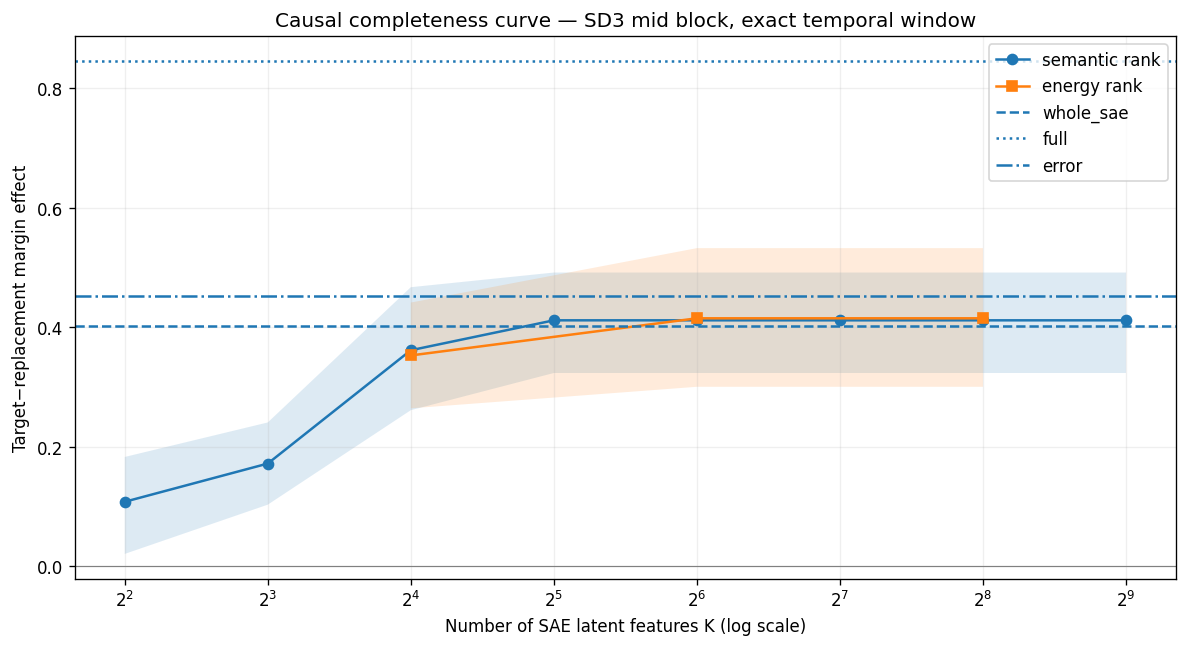

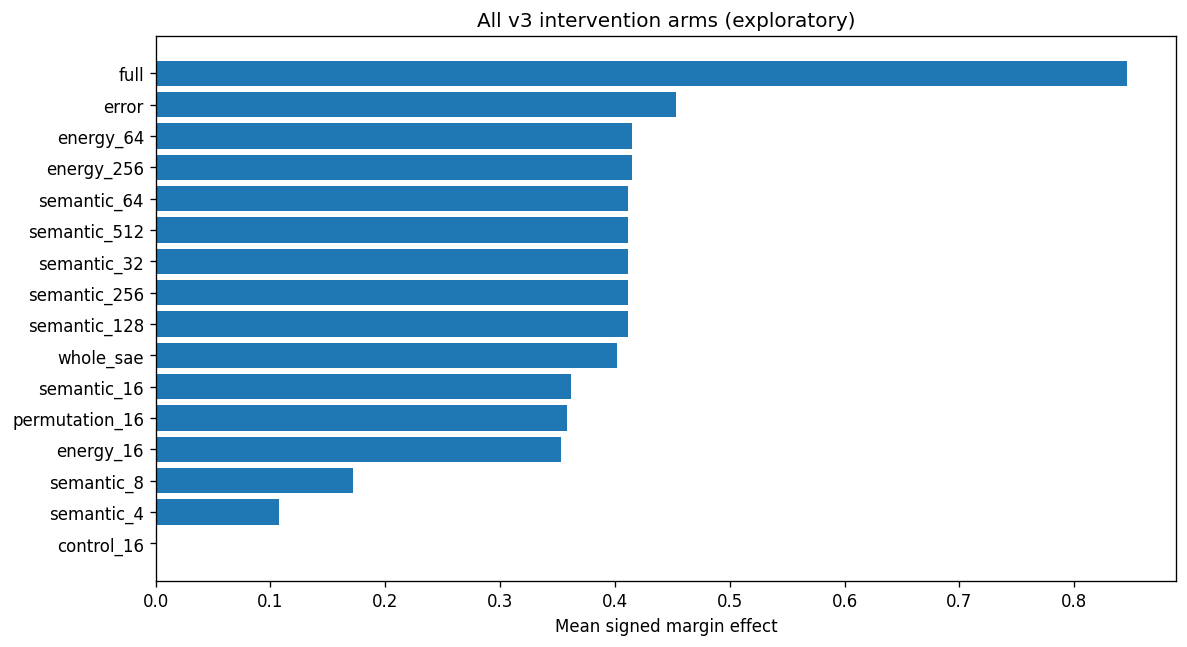

In [14]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"]=120
p=effects.copy()
fig,ax=plt.subplots(figsize=(10,5.5))
for kind,marker in [("semantic","o"),("energy","s")]:
    sub=p[p.arm.str.startswith(kind+"_")].copy()
    if sub.empty: continue
    sub["k"]=sub.arm.str.rsplit("_",n=1).str[-1].astype(int)
    rows=[]
    for k,g in sub.groupby("k"):
        lo,hi=label_cluster_bootstrap(g,"margin_effect")
        rows.append((k,g.margin_effect.mean(),lo,hi))
    m=np.array(sorted(rows),float)
    ax.plot(m[:,0],m[:,1],marker=marker,label=f"{kind} rank")
    ax.fill_between(m[:,0],m[:,2],m[:,3],alpha=.15)
for arm,ls in [("whole_sae","--"),("full",":"),("error","-.")]:
    if arm in set(summary.arm):
        ax.axhline(float(summary.set_index("arm").loc[arm,"margin_effect"]),linestyle=ls,label=arm)
ax.set(xlabel="Number of SAE latent features K (log scale)",ylabel="Target−replacement margin effect",title="Causal completeness curve — SD3 mid block, exact temporal window")
ax.set_xscale("log",base=2);ax.axhline(0,color="gray",linewidth=.7);ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/"figures"/"01_completeness_curve.png",dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(10,5.5))
order=summary.sort_values("margin_effect")
ax.barh(order.arm,order.margin_effect)
ax.axvline(0,color="gray",lw=1);ax.set(xlabel="Mean signed margin effect",title="All v3 intervention arms (exploratory)")
fig.tight_layout();fig.savefig(OUT/"figures"/"02_component_effects.png",dpi=180);plt.show()


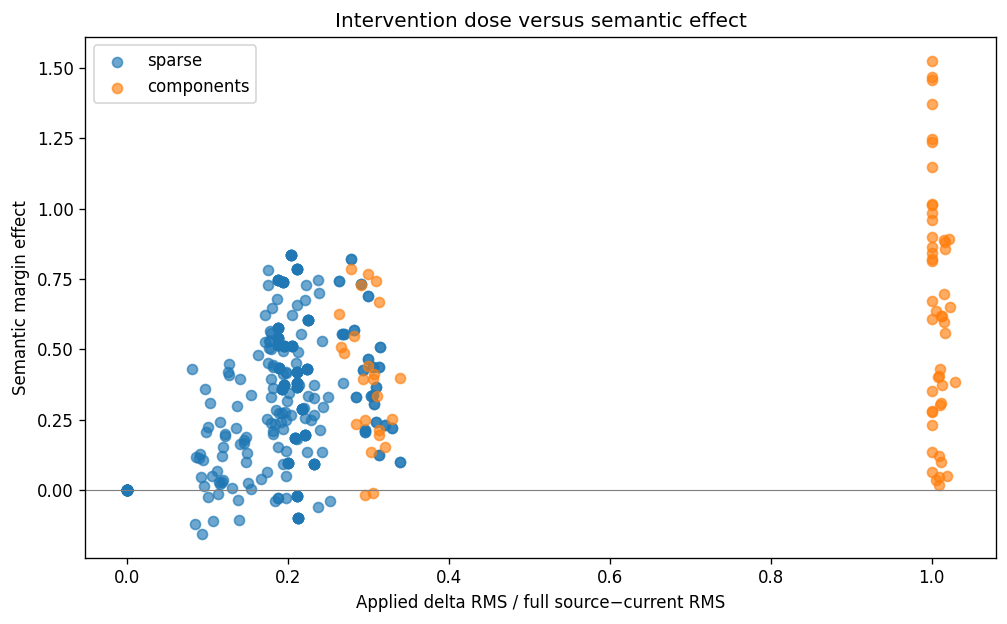

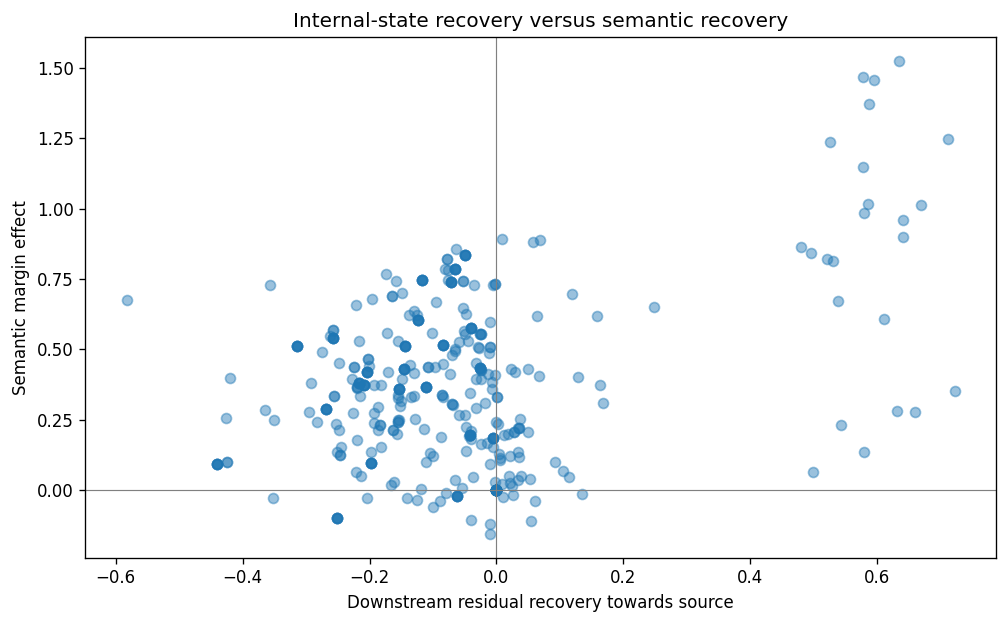

In [15]:
fig,ax=plt.subplots(figsize=(8.5,5.3))
sub=effects.dropna(subset=["mean_dose_ratio","margin_effect"])
for arm_group,selection in [("sparse",sub[sub.arm.str.contains("semantic_|energy_|control_|permutation_")]),
                            ("components",sub[sub.arm.isin(["whole_sae","error","full"])])]:
    ax.scatter(selection.mean_dose_ratio,selection.margin_effect,label=arm_group,alpha=.65)
ax.axhline(0,color="gray",lw=.7)
ax.set(xlabel="Applied delta RMS / full source−current RMS",ylabel="Semantic margin effect",title="Intervention dose versus semantic effect")
ax.legend();fig.tight_layout();fig.savefig(OUT/"figures"/"03_dose_vs_effect.png",dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(8.5,5.3))
sub=effects.dropna(subset=["probe_recovery","margin_effect"])
ax.scatter(sub.probe_recovery,sub.margin_effect,alpha=.45)
ax.axhline(0,color="gray",lw=.7);ax.axvline(0,color="gray",lw=.7)
ax.set(xlabel="Downstream residual recovery towards source",ylabel="Semantic margin effect",title="Internal-state recovery versus semantic recovery")
fig.tight_layout();fig.savefig(OUT/"figures"/"04_probe_vs_margin.png",dpi=180);plt.show()


## 11. Per-label diagnostics, specificity, and context preservation



arm,control_16,error,full,semantic_4,semantic_512,whole_sae
label,,,,,,
bicycle,0.0,0.686,1.225,0.090,0.498,0.628
book,0.0,0.492,0.811,0.238,0.474,0.522
car,0.0,0.245,0.688,0.193,0.445,0.205
cat,0.0,0.411,0.838,0.143,0.517,0.542
dog,0.0,0.420,0.727,0.075,0.224,0.253
person,0.0,0.462,0.789,-0.094,0.310,0.257


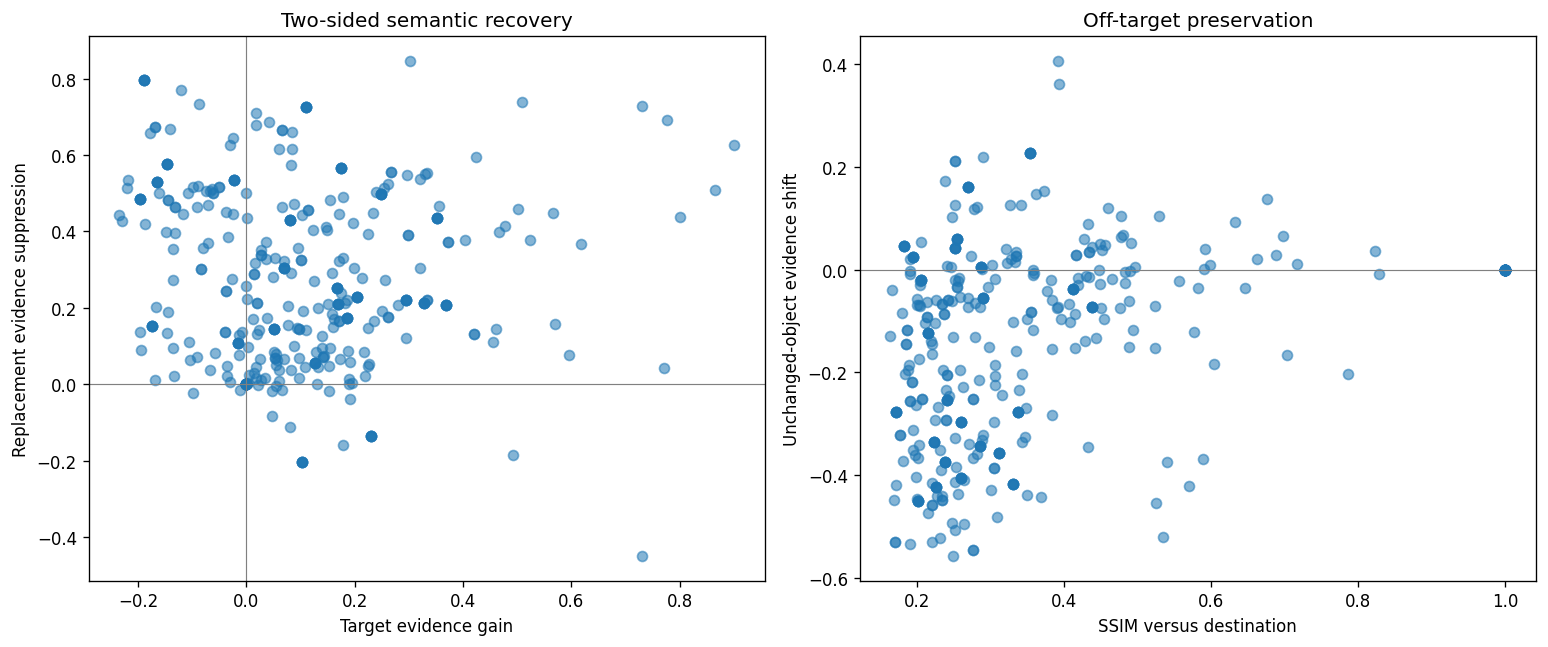

In [16]:
small=["full","whole_sae","error",f"semantic_{K_GRID[0]}",f"semantic_{K_GRID[-1]}",f"control_{16 if 16 in K_GRID else K_GRID[0]}"]
label_table=effects[effects.arm.isin(small)].groupby(["label","arm"],as_index=False).agg(margin=("margin_effect","mean"),target=("target_effect","mean"),replacement_suppression=("replacement_suppression","mean"),context_change=("context_change","mean"),ssim=("ssim","mean"))
label_table.to_csv(OUT/"per_label_summary.csv",index=False)
display(label_table.pivot(index="label",columns="arm",values="margin").round(3))

fig,axs=plt.subplots(1,2,figsize=(13,5.5))
axs[0].scatter(effects.target_effect,effects.replacement_suppression,alpha=.55)
axs[0].axhline(0,color="gray",lw=.7);axs[0].axvline(0,color="gray",lw=.7)
axs[0].set(xlabel="Target evidence gain",ylabel="Replacement evidence suppression",title="Two-sided semantic recovery")
axs[1].scatter(effects.ssim,effects.context_change,alpha=.55)
axs[1].axhline(0,color="gray",lw=.7)
axs[1].set(xlabel="SSIM versus destination",ylabel="Unchanged-object evidence shift",title="Off-target preservation")
fig.tight_layout();fig.savefig(OUT/"figures"/"05_semantic_specificity.png",dpi=180);plt.show()


## 12. Counterfactual image galleries



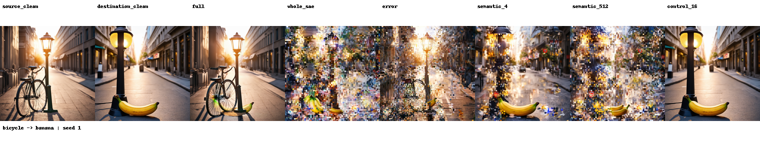

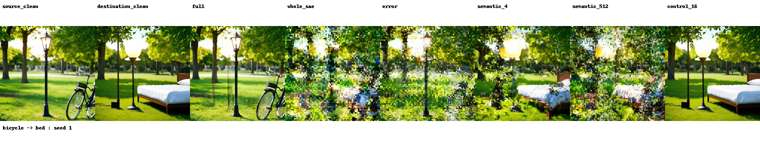

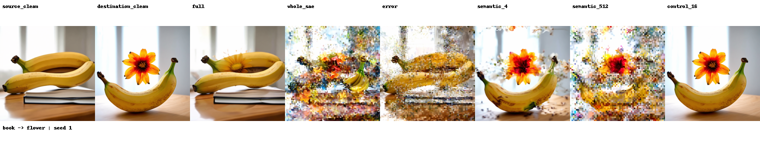

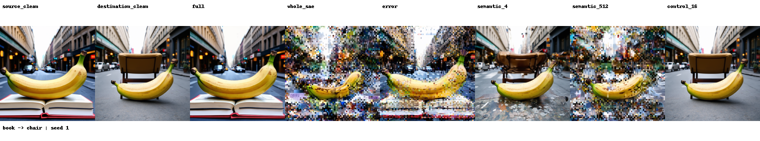

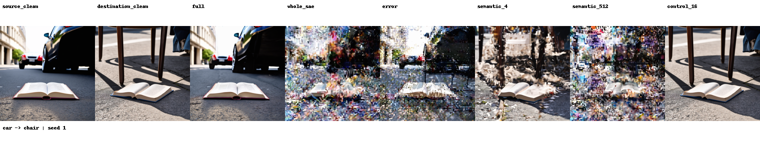

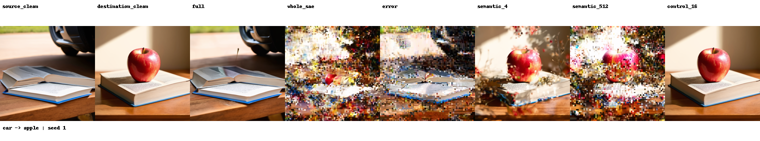

In [19]:
def make_gallery(pair,seed,thumb=(190,190)):
    label=pair["label"]; choices=["source_clean","destination_clean","full","whole_sae","error",f"semantic_{K_GRID[0]}",f"semantic_{K_GRID[-1]}",f"control_{16 if 16 in K_GRID else K_GRID[0]}"]
    entries=[]
    for arm in choices:
        if arm=="source_clean":p=locate_image(pair["pair_id"],seed,"source")
        elif arm=="destination_clean":p=locate_image(pair["pair_id"],seed,"destination")
        else:p=intervention_paths(pair,seed,arm)[0]
        if p and p.exists():entries.append((arm,p))
    title_h=52;w,h=thumb
    canvas=Image.new("RGB",(len(entries)*w,h+title_h+40),"white");draw=ImageDraw.Draw(canvas)
    for j,(arm,path) in enumerate(entries):
        im=Image.open(path).convert("RGB");im.thumbnail(thumb)
        px=j*w+(w-im.width)//2; py=title_h+(h-im.height)//2
        canvas.paste(im,(px,py))
        draw.text((j*w+5,7),arm[:26],fill="black")
    draw.text((6,h+title_h+8),f"{label} -> {pair['replacement_label']} | seed {seed}",fill="black")
    return canvas
for pair in PAIRS[:min(6,len(PAIRS))]:
    seed=SEEDS[0]
    image=make_gallery(pair,seed)
    fn=OUT/"galleries"/f"{pair['pair_id']}__seed_{seed:04d}.png"
    image.save(fn)
    display(image.resize((max(1,image.width//2),max(1,image.height//2))))


## 13. Interpretation gates, missing-causal-mass analysis and reproducibility report

In [18]:
full=summary.set_index("arm").loc["full","margin_effect"]
whole=summary.set_index("arm").loc["whole_sae","margin_effect"]
error=summary.set_index("arm").loc["error","margin_effect"]
maxk=f"semantic_{K_GRID[-1]}";maxeff=summary.set_index("arm").loc[maxk,"margin_effect"]
selected=f"semantic_{16 if 16 in K_GRID else K_GRID[0]}"
ctrl=f"control_{16 if 16 in K_GRID else K_GRID[0]}"
permut=f"permutation_{16 if 16 in K_GRID else K_GRID[0]}"
report={"mode":MODE,"n_templates":len(PAIRS),"seeds":SEEDS,"n_pair_seeds":len(PAIRS)*len(SEEDS),
        "full_mean_margin_effect":float(full),"whole_sae_mean_margin_effect":float(whole),"error_mean_margin_effect":float(error),
        "maxk_mean_margin_effect":float(maxeff),"semantic_k_minus_control_mean":float(summary.set_index("arm").loc[selected,"margin_effect"]-summary.set_index("arm").loc[ctrl,"margin_effect"]),
        "semantic_k_minus_permutation_mean":float(summary.set_index("arm").loc[selected,"margin_effect"]-summary.set_index("arm").loc[permut,"margin_effect"]),
        "mean_context_abs_shift":float(effects.context_change.abs().mean()),"median_ssim":float(effects.ssim.median()),
        "n_valid_pair_seeds":int(effects[effects.arm.eq("full")].site_valid.sum()),"ranking_hash":RANKS_HASH,
        "caveat":"Exploratory post-notebook-09 diagnostic; seeds 1/2 on inspected prompt templates are robustness tests, not independent confirmatory prompts."}
(OUT/"diagnostic_report.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
display(pd.DataFrame([report]).T.rename(columns={0:"Value"}))
print("\nIf full is strong but whole SAE and large-K remain weak, test higher-fidelity SAE reconstruction on held-out training prompts before asserting feature-level causal failure.")
print("If whole SAE approaches full, but low-K remains weak, test correlated feature sets and non-additive interactions.")
print("If permutation or matched controls approach sparse-target effects, do not claim object-specific sparse mediation.")
print("If all interventions damage context, report global state control rather than local object mechanism.")


,Value
mode,replication
n_templates,12
seeds,"[1, 2]"
n_pair_seeds,24
full_mean_margin_effect,0.846226
whole_sae_mean_margin_effect,0.401365
error_mean_margin_effect,0.452845
maxk_mean_margin_effect,0.411367
semantic_k_minus_control_mean,0.361276
semantic_k_minus_permutation_mean,0.003295



If full is strong but whole SAE and large-K remain weak, test higher-fidelity SAE reconstruction on held-out training prompts before asserting feature-level causal failure.
If whole SAE approaches full, but low-K remains weak, test correlated feature sets and non-additive interactions.
If permutation or matched controls approach sparse-target effects, do not claim object-specific sparse mediation.
If all interventions damage context, report global state control rather than local object mechanism.
